<a href="https://colab.research.google.com/github/iamalenn6/student-performance-audit/blob/main/3stage_part2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split

from sklearn.preprocessing import (
    StandardScaler,
    MinMaxScaler,
    RobustScaler
)

In [6]:
import os
files = os.listdir('/content')
print('Файлы в рабочей папке:')
for file in files:
  print(file)

Файлы в рабочей папке:
.config
Student_Performance_cleaned.csv
sample_data


In [7]:
df = pd.read_csv('/content/Student_Performance_cleaned.csv')
print('Размер датасета:')
print(df.shape)
print('\nПервые 5 строк:')
display(df.head())

Размер датасета:
(9873, 6)

Первые 5 строк:


,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
0,7,99,Yes,9,1,91.0
1,4,82,No,4,2,65.0
2,8,51,Yes,7,2,45.0
3,5,52,Yes,5,2,36.0
4,7,75,No,8,5,66.0


In [8]:
print("Информация о столбцах:")
df.info()

print("\nКоличество пропусков:")
print(df.isnull().sum())

print("\nОписательная статистика:")
display(df.describe())

Информация о столбцах:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9873 entries, 0 to 9872
Data columns (total 6 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Hours Studied                     9873 non-null   int64  
 1   Previous Scores                   9873 non-null   int64  
 2   Extracurricular Activities        9873 non-null   object 
 3   Sleep Hours                       9873 non-null   int64  
 4   Sample Question Papers Practiced  9873 non-null   int64  
 5   Performance Index                 9873 non-null   float64
dtypes: float64(1), int64(4), object(1)
memory usage: 462.9+ KB

Количество пропусков:
Hours Studied                       0
Previous Scores                     0
Extracurricular Activities          0
Sleep Hours                         0
Sample Question Papers Practiced    0
Performance Index                   0
dtype: int64

Описательная статистика:


,Hours Studied,Previous Scores,Sleep Hours,Sample Question Papers Practiced,Performance Index
count,9873.000000,9873.000000,9873.000000,9873.000000,9873.000000
mean,4.992100,69.441102,6.531652,4.583004,55.216651
std,2.589081,17.325601,1.697683,2.867202,19.208570
min,1.000000,40.000000,4.000000,0.000000,10.000000
25%,3.000000,54.000000,5.000000,2.000000,40.000000
50%,5.000000,69.000000,7.000000,5.000000,55.000000
75%,7.000000,85.000000,8.000000,7.000000,70.000000
max,9.000000,99.000000,9.000000,9.000000,100.000000


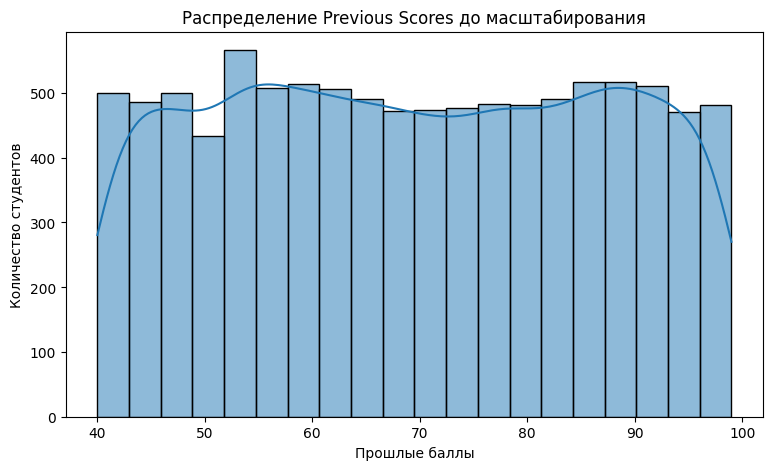

In [9]:
#строим график исходного признака "предыдущий балл"
plt.figure(figsize=(9,5))
sns.histplot(
    df['Previous Scores'],
    bins=20,
    kde=True
)
plt.title('Распределение Previous Scores до масштабирования')
plt.xlabel('Прошлые баллы')
plt.ylabel('Количество студентов')

plt.show()

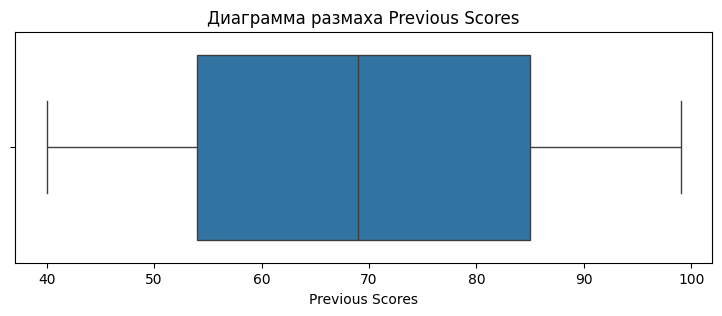

In [10]:
plt.figure(figsize=(9, 3))

sns.boxplot(x=df['Previous Scores'])

plt.title('Диаграмма размаха Previous Scores')
plt.xlabel('Previous Scores')

plt.show()

In [12]:
# отделяем признаки от целевой переменной
X = df.drop(columns=['Performance Index'])
y=df['Performance Index']

# разделяем данные на обучающую и тестовую выборки
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)
print('Размер обучающей выборки:', X_train.shape)
print('Размер тестовой выборки:', X_test.shape)

Размер обучающей выборки: (7898, 5)
Размер тестовой выборки: (1975, 5)


In [13]:
# применение StandardScaler
scaler_standard = StandardScaler()
# обучаем масштабировщик на обучающей выборке и одновременно преобразуем её
X_train_standard = scaler_standard.fit_transform(
    X_test[['Previous Scores']]
)

# применяем уже обученный масштабировщие к тестовой выборке
X_test_standard = scaler_standard.transform(
    X_test[['Previous Scores']]
)
# проверка результата
print("Среднее после масштабирования:",
      X_train_standard.mean())
print('Стандартное отклонение после масштабирования:',
    X_train_standard.mean())
print("Минимальное значение:",
      X_train_standard.min())

print("Максимальное значение:",
      X_train_standard.max())


Среднее после масштабирования: 3.4627715603498555e-16
Стандартное отклонение после масштабирования: 3.4627715603498555e-16
Минимальное значение: -1.7164164133674742
Максимальное значение: 1.6720702036193107


In [15]:
print("Среднее:", X_train_standard.mean())
print("Стандартное отклонение:", X_train_standard.std())
print("Первые 5 значений:")
print(X_train_standard[:5])

Среднее: 3.4627715603498555e-16
Стандартное отклонение: 0.9999999999999999
Первые 5 значений:
[[-0.33804898]
 [ 1.15518241]
 [ 0.17883881]
 [-1.54412048]
 [ 0.35113474]]


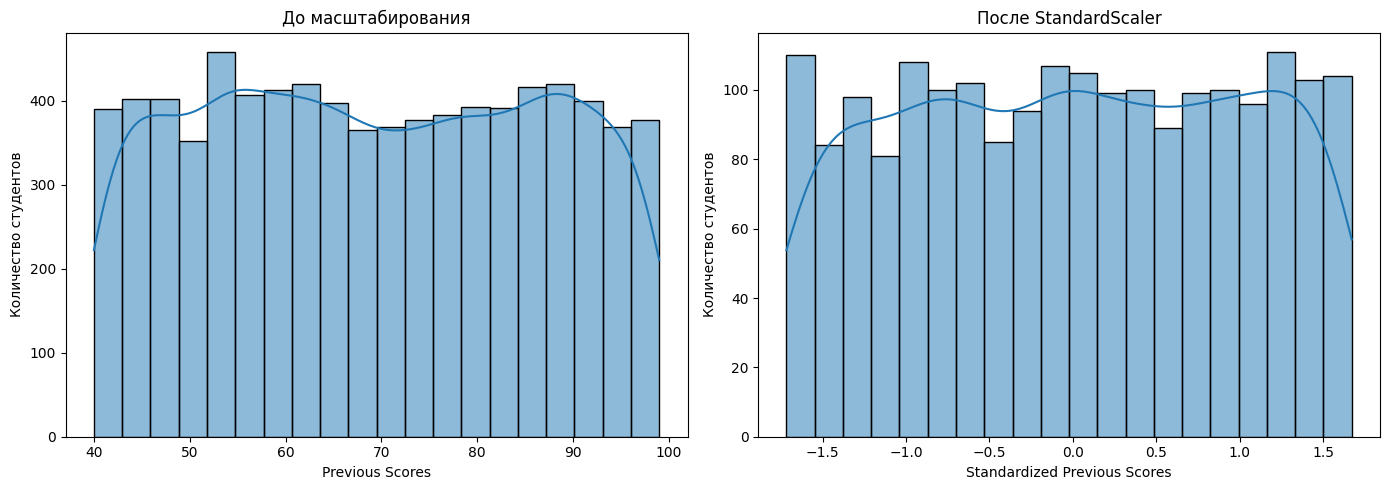

In [14]:
#создаем область для двух графиков
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
# исходное распределение
sns.histplot(
    X_train['Previous Scores'],
    bins=20,
    kde=True,
    ax=axes[0]
)
axes[0].set_title('До масштабирования')
axes[0].set_xlabel('Previous Scores')
axes[0].set_ylabel('Количество студентов')

# распределение после StandardScaler
sns.histplot(
    X_train_standard.flatten(),
    bins=20,
    kde=True,
    ax=axes[1]
)

axes[1].set_title('После StandardScaler')
axes[1].set_xlabel('Standardized Previous Scores')
axes[1].set_ylabel('Количество студентов')

plt.tight_layout()
plt.show()
